# MAGNET: Multi-scale Attention-based Graph Network with Ensemble Transfer Learning
# for Breast Cancer Histopathology Classification



## 1. Environment Setup & Imports

In [1]:
# ── Install missing packages (run once) ──────────────────────────────────────
import subprocess, sys

def pip_install(pkg):
    subprocess.check_call([sys.executable, '-m', 'pip', 'install', '-q', pkg])

try:
    import timm
except ImportError:
    pip_install('timm')

try:
    import captum
except ImportError:
    pip_install('captum')

# NOTE: We do NOT install dgl — we use a pure-PyTorch GNN
print('All packages ready.')

All packages ready.


In [2]:
import os, sys, glob, random, json, time, copy, warnings
warnings.filterwarnings('ignore')

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from PIL import Image
import cv2

from sklearn.metrics import (
    accuracy_score, precision_score, recall_score, f1_score,
    confusion_matrix, roc_auc_score, roc_curve, classification_report
)

import torch
import torch.nn as nn
import torch.nn.functional as F
import torch.optim as optim
from torch.utils.data import Dataset, DataLoader
from torch.cuda.amp import GradScaler, autocast
from torchvision import transforms, models
import timm
from tqdm import tqdm

# ── Reproducibility ──────────────────────────────────────────────────────────
def set_seed(seed=42):
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)
    if torch.cuda.is_available():
        torch.cuda.manual_seed_all(seed)
    torch.backends.cudnn.deterministic = True
    torch.backends.cudnn.benchmark = False

set_seed(42)

# ── Device ───────────────────────────────────────────────────────────────────
device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
print(f'Device: {device}')
if device.type == 'cuda':
    print(f'GPU: {torch.cuda.get_device_name(0)}')
    total_mb = torch.cuda.get_device_properties(0).total_memory / 1024**2
    print(f'VRAM: {total_mb:.0f} MB')

# ── Directories ───────────────────────────────────────────────────────────────
for d in ['results', 'checkpoints', 'logs', 'plots']:
    os.makedirs(d, exist_ok=True)

print('Setup complete.')

Device: cuda
GPU: NVIDIA GeForce GTX 1650
VRAM: 4096 MB
Setup complete.


## 2. Configuration (edit these)

In [3]:
DATA_ROOT = 'data/BreaKHis_v1/BreaKHis_v1/histology_slides/breast'

# ── Hardware / training knobs (tuned for GTX 1650 4 GB) ──────────────────────
BATCH_SIZE   = 4        # 4 forward passes (one per mag) in one step — keep at 4
# CRITICAL FIX: NUM_WORKERS must be 0 on Windows + Jupyter.
# With num_workers > 0, Python's multiprocessing can't fork inside a notebook
# on Windows → DataLoader workers deadlock → tqdm shows 0/N forever.
NUM_WORKERS  = 0
IMG_SIZE     = 224
FEAT_DIM     = 512      # projection dimension; 1024 will OOM on 4 GB
EPOCHS       = 50
LR           = 1e-4
WEIGHT_DECAY = 1e-5
EARLY_STOP   = 12
MAGNIFICATIONS = ['40X', '100X', '200X', '400X']

# Backbone names (timm) — all very small, pretrained on ImageNet-1k
BACKBONES = {
    '40X' : 'mobilenetv3_large_100',   # ~5.5M params
    '100X': 'efficientnet_b0',          # ~5.3M params
    '200X': 'resnet34',                 # ~21M params
    '400X': 'mobilenetv3_small_100',    # ~2.5M params
}
BACKBONE_OUT_DIM = {
    '40X' : 1280,   # mobilenetv3_large_100
    '100X': 1280,   # efficientnet_b0
    '200X': 512,    # resnet34
    '400X': 1024,   # mobilenetv3_small_100
}
print('Config loaded.')


Config loaded.


## 3. Data Preparation

### 3.1 Stain Normalisation (Macenko, simplified)

In [4]:
def macenko_norm(img_pil: Image.Image) -> Image.Image:
    """
    Simplified Macenko stain normalisation.
    Full Macenko requires SVD of optical-density matrix; here we do
    a colour-normalisation in OD space that is fast enough for on-the-fly use.
    For production use staintools (pip install staintools) for exact Macenko.
    """
    img = np.array(img_pil, dtype=np.float32)
    img = np.clip(img, 1, 255)           # avoid log(0)
    OD = -np.log(img / 255.0)           # optical density
    # Normalise each channel independently (z-score in OD space)
    for c in range(3):
        m = OD[..., c].mean()
        s = OD[..., c].std() + 1e-6
        OD[..., c] = (OD[..., c] - m) / s * 0.3 + 0.4  # target OD ~ N(0.4, 0.3)
    img_norm = np.exp(-OD) * 255.0
    img_norm = np.clip(img_norm, 0, 255).astype(np.uint8)
    return Image.fromarray(img_norm)

print('Stain normalizer defined.')

Stain normalizer defined.


### 3.2 Patient-wise Split

In [5]:
BENIGN_SUBS    = ['adenosis', 'fibroadenoma', 'phyllodes_tumor', 'tubular_adenoma']
MALIGNANT_SUBS = ['ductal_carcinoma', 'lobular_carcinoma', 'mucinous_carcinoma', 'papillary_carcinoma']
ALL_SUBS       = BENIGN_SUBS + MALIGNANT_SUBS
SUB2IDX        = {s: i for i, s in enumerate(ALL_SUBS)}

def collect_patient_info(root_dir):
    """
    Returns a dict:
      patient_id -> {
        'binary': 0|1,
        'subtype': int,
        'paths': {mag: [path, ...]}
      }
    """
    patients = {}
    for cls_name, binary, subs in [('benign', 0, BENIGN_SUBS), ('malignant', 1, MALIGNANT_SUBS)]:
        cls_path = os.path.join(root_dir, cls_name, 'SOB')
        if not os.path.isdir(cls_path):
            continue
        for sub in subs:
            sub_path = os.path.join(cls_path, sub)
            if not os.path.isdir(sub_path):
                continue
            for patient_dir in os.listdir(sub_path):
                pat_path = os.path.join(sub_path, patient_dir)
                if not os.path.isdir(pat_path):
                    continue
                if patient_dir not in patients:
                    patients[patient_dir] = {
                        'binary' : binary,
                        'subtype': SUB2IDX[sub],
                        'paths'  : {m: [] for m in MAGNIFICATIONS}
                    }
                for mag in MAGNIFICATIONS:
                    mag_path = os.path.join(pat_path, mag)
                    if os.path.isdir(mag_path):
                        for f in os.listdir(mag_path):
                            if f.lower().endswith('.png'):
                                patients[patient_dir]['paths'][mag].append(
                                    os.path.join(mag_path, f)
                                )
    return patients


if not os.path.isdir(DATA_ROOT):
    print(f'[WARNING] {DATA_ROOT} not found — using SYNTHETIC DATA for demonstration.')
    print('Download BreakHis and set DATA_ROOT to run with real data.')
    SYNTHETIC = True
else:
    SYNTHETIC = False
    patient_info = collect_patient_info(DATA_ROOT)
    all_patients = list(patient_info.keys())
    print(f'Total patients: {len(all_patients)}')

    # Patient-wise 70/15/15 split
    random.seed(42)
    random.shuffle(all_patients)
    n = len(all_patients)
    train_patients = all_patients[:int(0.70 * n)]
    val_patients   = all_patients[int(0.70 * n):int(0.85 * n)]
    test_patients  = all_patients[int(0.85 * n):]
    print(f'Train: {len(train_patients)} | Val: {len(val_patients)} | Test: {len(test_patients)}')

Total patients: 82
Train: 57 | Val: 12 | Test: 13


### 3.3 Synthetic Data Fallback (for dry-run without BreakHis)

In [6]:
if SYNTHETIC:
    # Build fake patient_info with random tensors so the full pipeline can be tested
    N_PATIENTS = 80
    patient_info = {}
    for i in range(N_PATIENTS):
        pid = f'patient_{i:03d}'
        binary  = i % 2
        subtype = i % 8
        patient_info[pid] = {
            'binary' : binary,
            'subtype': subtype,
            'paths'  : {m: [None] * 5 for m in MAGNIFICATIONS}  # None = will generate random tensor
        }
    all_patients   = list(patient_info.keys())
    random.seed(42); random.shuffle(all_patients)
    n = len(all_patients)
    train_patients = all_patients[:int(0.70 * n)]
    val_patients   = all_patients[int(0.70 * n):int(0.85 * n)]
    test_patients  = all_patients[int(0.85 * n):]
    print(f'[SYNTHETIC] Train: {len(train_patients)} | Val: {len(val_patients)} | Test: {len(test_patients)}')

### 3.4 Multi-Magnification Dataset

In [7]:
class MultiMagDataset(Dataset):
    """
    Each __getitem__ returns one image from each of the 4 magnifications
    for a given patient (sampled randomly from available images),
    plus binary and subtype labels.

    FIX: use numpy rng (not random.choice) to avoid multiprocessing seed collisions.
    """

    def __init__(self, patient_ids, patient_info, transform=None,
                 stain_norm=True, img_size=224, synthetic=False):
        self.patient_ids  = patient_ids
        self.patient_info = patient_info
        self.transform    = transform
        self.stain_norm   = stain_norm
        self.img_size     = img_size
        self.synthetic    = synthetic

    def __len__(self):
        return len(self.patient_ids)

    def _load(self, path) -> torch.Tensor:
        if self.synthetic or path is None:
            return torch.randn(3, self.img_size, self.img_size)
        img = Image.open(path).convert('RGB')
        img = img.resize((self.img_size, self.img_size), Image.BILINEAR)
        if self.stain_norm:
            img = macenko_norm(img)
        if self.transform:
            img = self.transform(img)
        return img

    def __getitem__(self, idx):
        pid  = self.patient_ids[idx]
        info = self.patient_info[pid]
        # Use numpy rng seeded by idx — safe with num_workers=0 and any workers
        rng  = np.random.default_rng(seed=None)  # new RNG per call, no shared state
        imgs = []
        for mag in MAGNIFICATIONS:
            paths = info['paths'][mag]
            if paths:
                path = paths[rng.integers(len(paths))]
            else:
                path = None
            imgs.append(self._load(path))
        return (*imgs, int(info['binary']), int(info['subtype']))


# ── Transforms ────────────────────────────────────────────────────────────────
mean = [0.485, 0.456, 0.406]
std  = [0.229, 0.224, 0.225]

train_tf = transforms.Compose([
    transforms.RandomHorizontalFlip(),
    transforms.RandomVerticalFlip(),
    transforms.RandomRotation(180),
    transforms.ColorJitter(brightness=0.2, contrast=0.2, saturation=0.2, hue=0.05),
    transforms.ToTensor(),
    transforms.Normalize(mean, std),
])
val_tf = transforms.Compose([
    transforms.ToTensor(),
    transforms.Normalize(mean, std),
])


def make_loader(patients, transform, shuffle, synthetic=SYNTHETIC):
    ds = MultiMagDataset(patients, patient_info, transform=transform,
                         stain_norm=(not synthetic), img_size=IMG_SIZE,
                         synthetic=synthetic)
    # num_workers=0 is REQUIRED on Windows + Jupyter to avoid deadlock.
    # On Linux you can set num_workers=2 for a small speedup.
    return DataLoader(ds, batch_size=BATCH_SIZE, shuffle=shuffle,
                      num_workers=NUM_WORKERS, pin_memory=(NUM_WORKERS > 0),
                      drop_last=True if shuffle else False)

train_loader = make_loader(train_patients, train_tf, shuffle=True)
val_loader   = make_loader(val_patients,   val_tf,   shuffle=False)
test_loader  = make_loader(test_patients,  val_tf,   shuffle=False)

print(f'Loaders ready — train={len(train_loader.dataset)} '
      f'val={len(val_loader.dataset)} '
      f'test={len(test_loader.dataset)}')
print(f'Batches per epoch (train): {len(train_loader)}')

# Quick sanity check: grab one batch and verify shapes
print('Running single-batch sanity check...')
_b = next(iter(train_loader))
print(f'  Batch shapes: {[t.shape for t in _b[:4]]}')
print(f'  Labels (binary): {_b[4]}')
print('Sanity check passed — DataLoader is working correctly.')
del _b


Loaders ready — train=57 val=12 test=13
Batches per epoch (train): 14
Running single-batch sanity check...
  Batch shapes: [torch.Size([4, 3, 224, 224]), torch.Size([4, 3, 224, 224]), torch.Size([4, 3, 224, 224]), torch.Size([4, 3, 224, 224])]
  Labels (binary): tensor([1, 1, 1, 1])
Sanity check passed — DataLoader is working correctly.


## 4. Model Definition: MAGNET

### 4.1 Multi-Branch Feature Extractor

In [8]:
class BranchExtractor(nn.Module):
    """Single pretrained backbone + linear projection."""

    def __init__(self, backbone_name: str, in_dim: int, out_dim: int, pretrained=True):
        super().__init__()
        self.backbone = timm.create_model(backbone_name, pretrained=pretrained,
                                          num_classes=0, global_pool='avg')
        self.proj = nn.Sequential(
            nn.Linear(in_dim, out_dim),
            nn.LayerNorm(out_dim),
            nn.GELU(),
        )
        # Cache raw features for auxiliary head
        self._raw_dim = in_dim

    def forward(self, x):
        raw = self.backbone(x)          # [B, in_dim]
        proj = self.proj(raw)           # [B, out_dim]
        return raw, proj

print('BranchExtractor defined.')

BranchExtractor defined.


### 4.2 Cross-Magnification Attention Fusion

In [9]:
class CrossMagFusion(nn.Module):
    """
    Multi-head self-attention across 4 magnification tokens.
    Each token is a projected feature vector of dim `feat_dim`.
    Returns fused representation + attention weight matrix.
    """

    def __init__(self, feat_dim=512, num_heads=8, dropout=0.1):
        super().__init__()
        assert feat_dim % num_heads == 0, 'feat_dim must be divisible by num_heads'
        self.attn = nn.MultiheadAttention(
            embed_dim=feat_dim, num_heads=num_heads,
            dropout=dropout, batch_first=True
        )
        # Learnable per-magnification scale (softmax-normalised)
        self.mag_scale = nn.Parameter(torch.ones(4))
        self.ffn = nn.Sequential(
            nn.Linear(feat_dim, feat_dim * 2),
            nn.GELU(),
            nn.Dropout(dropout),
            nn.Linear(feat_dim * 2, feat_dim),
        )
        self.norm1 = nn.LayerNorm(feat_dim)
        self.norm2 = nn.LayerNorm(feat_dim)

    def forward(self, feats):
        """
        feats: list of 4 tensors, each [B, feat_dim]
        returns: fused [B, feat_dim], attn_weights [B, 4, 4]
        """
        x = torch.stack(feats, dim=1)                       # [B, 4, feat_dim]
        attn_out, attn_w = self.attn(x, x, x)              # [B, 4, feat_dim], [B, 4, 4]
        x = self.norm1(x + attn_out)                        # residual
        # Weighted aggregate
        w = F.softmax(self.mag_scale, dim=0)                # [4]
        fused = (x * w.unsqueeze(0).unsqueeze(-1)).sum(1)   # [B, feat_dim]
        fused = self.norm2(fused + self.ffn(fused))         # FFN + residual
        return fused, attn_w

print('CrossMagFusion defined.')

CrossMagFusion defined.


### 4.3 Pure-PyTorch Sparse GNN (no DGL / no extra CUDA compile)

In [10]:
class SparseGraphConv(nn.Module):
    """
    One layer of graph convolution: h' = D^{-0.5} A D^{-0.5} H W
    A is built on-the-fly from cosine similarity of node features.
    Works entirely on CUDA tensors — no DGL required.
    """

    def __init__(self, in_dim, out_dim):
        super().__init__()
        self.W = nn.Linear(in_dim, out_dim, bias=False)

    def forward(self, h, adj):
        # adj: [B, B] normalised adjacency
        # h  : [B, in_dim]
        return F.relu(adj @ self.W(h))


class BatchGraphNet(nn.Module):
    """
    Treats each batch of patient embeddings as nodes in a graph.
    Edges = cosine similarity > threshold.
    After 2 GCN layers the node representations are mean-pooled and
    added back to the input (residual).
    """

    def __init__(self, feat_dim=512, hidden_dim=256, num_layers=2,
                 sim_threshold=0.5, dropout=0.1):
        super().__init__()
        self.threshold = sim_threshold
        layers = []
        in_d = feat_dim
        for _ in range(num_layers):
            layers.append(SparseGraphConv(in_d, hidden_dim))
            in_d = hidden_dim
        self.gcn_layers = nn.ModuleList(layers)
        self.drop       = nn.Dropout(dropout)
        self.readout    = nn.Linear(hidden_dim, feat_dim)
        self.norm       = nn.LayerNorm(feat_dim)

    def _build_adj(self, h: torch.Tensor) -> torch.Tensor:
        """
        Normalised adjacency from cosine similarity + self-loops.
        h: [B, D] -> adj: [B, B]
        """
        norm = F.normalize(h.detach(), p=2, dim=1)      # detach so grad doesn't flow through adj
        sim  = torch.mm(norm, norm.t())                  # [B, B]
        mask = (sim > self.threshold).float()
        mask.fill_diagonal_(1.0)                         # self-loops
        # Symmetric normalisation D^{-0.5} A D^{-0.5}
        deg  = mask.sum(dim=1, keepdim=True).clamp(min=1)
        d_inv_sqrt = deg.pow(-0.5)
        adj  = mask * d_inv_sqrt * d_inv_sqrt.t()
        return adj

    def forward(self, h):
        """h: [B, feat_dim]  ->  h': [B, feat_dim] (residual)"""
        adj = self._build_adj(h)           # [B, B]
        out = h
        for layer in self.gcn_layers:
            out = self.drop(layer(out, adj))
        # Residual addition
        return self.norm(h + self.readout(out))

print('BatchGraphNet defined (pure PyTorch, no DGL).')

BatchGraphNet defined (pure PyTorch, no DGL).


### 4.4 MAGNET Full Model

In [11]:
class MAGNET(nn.Module):
    """
    Multi-scale Attention-based Graph Network with Ensemble Transfer Learning.

    Architecture:
      • 4 lightweight pretrained backbones (one per magnification)
      • Feature projection to shared feat_dim
      • Cross-magnification multi-head attention fusion
      • Batch graph network for inter-sample relationship modelling
      • Dual heads: binary (B/M) + subtype (8-class)
      • Auxiliary per-branch binary heads (deep supervision)
      • Uncertainty head (MC-Dropout compatible)
    """

    def __init__(self, feat_dim=FEAT_DIM, num_binary=2, num_subtype=8,
                 pretrained=True, use_gnn=True, use_aux=True):
        super().__init__()
        self.use_gnn = use_gnn
        self.use_aux = use_aux

        # ── Backbone branches ──────────────────────────────────────────────
        self.branches = nn.ModuleDict()
        for mag in MAGNIFICATIONS:
            self.branches[mag] = BranchExtractor(
                BACKBONES[mag], BACKBONE_OUT_DIM[mag], feat_dim, pretrained
            )

        # ── Cross-magnification fusion ─────────────────────────────────────
        self.fusion = CrossMagFusion(feat_dim, num_heads=8)

        # ── Graph network ──────────────────────────────────────────────────
        if use_gnn:
            self.gnn = BatchGraphNet(feat_dim, hidden_dim=256)

        # ── Main classification heads ──────────────────────────────────────
        def _head(in_d, out_d):
            return nn.Sequential(
                nn.Linear(in_d, 256),
                nn.BatchNorm1d(256),
                nn.GELU(),
                nn.Dropout(0.4),
                nn.Linear(256, out_d),
            )

        self.binary_head  = _head(feat_dim, num_binary)
        self.subtype_head = _head(feat_dim, num_subtype)

        # ── Uncertainty head ───────────────────────────────────────────────
        self.uncertainty_head = nn.Sequential(
            nn.Linear(feat_dim, 128),
            nn.ReLU(),
            nn.Dropout(0.5),
            nn.Linear(128, 1),
            nn.Sigmoid(),
        )

        # ── Auxiliary per-branch heads (deep supervision) ──────────────────
        if use_aux:
            self.aux_heads = nn.ModuleDict({
                mag: nn.Linear(BACKBONE_OUT_DIM[mag], num_binary)
                for mag in MAGNIFICATIONS
            })

    def forward(self, x40, x100, x200, x400, return_attn=False):
        inputs = {'40X': x40, '100X': x100, '200X': x200, '400X': x400}
        raws, projs, aux_logits = {}, {}, {}

        for mag in MAGNIFICATIONS:
            raw, proj = self.branches[mag](inputs[mag])
            raws[mag]  = raw
            projs[mag] = proj
            if self.use_aux:
                aux_logits[mag] = self.aux_heads[mag](raw)

        # Fusion
        feat_list = [projs[m] for m in MAGNIFICATIONS]
        fused, attn_w = self.fusion(feat_list)            # [B, feat_dim], [B, 4, 4]

        # GNN
        if self.use_gnn:
            fused = self.gnn(fused)

        binary_logits  = self.binary_head(fused)
        subtype_logits = self.subtype_head(fused)
        uncertainty    = self.uncertainty_head(fused)     # [B, 1]

        out = (binary_logits, subtype_logits, uncertainty,
               list(aux_logits.values()) if self.use_aux else [])
        if return_attn:
            return (*out, attn_w)
        return out

    @torch.no_grad()
    def mc_uncertainty(self, x40, x100, x200, x400, n_passes=20):
        """Monte-Carlo Dropout uncertainty estimate (enable dropout at inference)."""
        self.train()       # keeps dropout active
        probs = []
        for _ in range(n_passes):
            logits, *_ = self(x40, x100, x200, x400)
            probs.append(F.softmax(logits, dim=1).unsqueeze(0))
        self.eval()
        probs = torch.cat(probs, dim=0)    # [n_passes, B, 2]
        mean  = probs.mean(0)              # [B, 2]
        var   = probs.var(0)               # [B, 2]  — epistemic uncertainty
        return mean, var

print('MAGNET defined.')

MAGNET defined.


### 4.5 Smoke-test forward pass

In [12]:
torch.cuda.empty_cache()
model = MAGNET(pretrained=False, use_gnn=True, use_aux=True).to(device)  # pretrained=False for quick test

total_params = sum(p.numel() for p in model.parameters())
trainable    = sum(p.numel() for p in model.parameters() if p.requires_grad)
print(f'Total params  : {total_params/1e6:.2f} M')
print(f'Trainable     : {trainable/1e6:.2f} M')

B = 4
dummy = [torch.randn(B, 3, IMG_SIZE, IMG_SIZE).to(device) for _ in range(4)]
with torch.amp.autocast(device_type=device.type):
    out = model(*dummy, return_attn=True)
bl, sl, unc, aux, aw = out
print(f'binary logits  : {bl.shape}')
print(f'subtype logits : {sl.shape}')
print(f'uncertainty    : {unc.shape}')
print(f'aux heads      : {[a.shape for a in aux]}')
print(f'attn weights   : {aw.shape}')

if device.type == 'cuda':
    used_mb = torch.cuda.memory_allocated() / 1024**2
    print(f'VRAM used (forward only): {used_mb:.0f} MB')

del model  # free before reloading with pretrained weights below
torch.cuda.empty_cache()
print('Smoke test passed.')


Total params  : 35.89 M
Trainable     : 35.89 M
binary logits  : torch.Size([4, 2])
subtype logits : torch.Size([4, 8])
uncertainty    : torch.Size([4, 1])
aux heads      : [torch.Size([4, 2]), torch.Size([4, 2]), torch.Size([4, 2]), torch.Size([4, 2])]
attn weights   : torch.Size([4, 4, 4])
VRAM used (forward only): 578 MB
Smoke test passed.


## 5. Training Pipeline

### 5.1 Loss Function

In [13]:
class MAGNETLoss(nn.Module):
    """
    Weighted multi-task loss:
      L = α·L_binary + β·L_subtype + γ·L_aux + δ·L_unc
    """

    def __init__(self, alpha=1.0, beta=0.5, gamma=0.3, delta=0.05,
                 class_weights=None):
        super().__init__()
        self.alpha = alpha
        self.beta  = beta
        self.gamma = gamma
        self.delta = delta
        # Class-weighted CE for imbalanced B/M split in BreakHis (~31% benign)
        w = class_weights if class_weights is not None else torch.tensor([0.69, 0.31])
        self.ce_binary  = nn.CrossEntropyLoss(weight=w)
        self.ce_subtype = nn.CrossEntropyLoss()
        self.ce_aux     = nn.CrossEntropyLoss()
        self.mse        = nn.MSELoss()

    def forward(self, binary_logits, subtype_logits, uncertainty, aux_logits,
                y_bin, y_sub):
        # Move weights to same device as logits
        self.ce_binary.weight = self.ce_binary.weight.to(binary_logits.device)

        L_bin = self.ce_binary(binary_logits, y_bin)
        L_sub = self.ce_subtype(subtype_logits, y_sub)

        L_aux = torch.tensor(0.0, device=binary_logits.device)
        if aux_logits:
            for aux in aux_logits:
                L_aux = L_aux + self.ce_aux(aux, y_bin)
            L_aux = L_aux / len(aux_logits)

        # Uncertainty: penalise high uncertainty on high-confidence predictions
        with torch.no_grad():
            conf = F.softmax(binary_logits, dim=1).max(dim=1).values  # [B]
            target_unc = (1.0 - conf).unsqueeze(1)                    # [B, 1]
        L_unc = self.mse(uncertainty, target_unc)

        total = (self.alpha * L_bin + self.beta * L_sub +
                 self.gamma * L_aux + self.delta * L_unc)

        return total, {
            'binary' : L_bin.item(),
            'subtype': L_sub.item(),
            'aux'    : L_aux.item(),
            'unc'    : L_unc.item(),
        }

print('MAGNETLoss defined.')

MAGNETLoss defined.


### 5.2 Epoch-level Train / Validate Loops

In [14]:
def train_epoch(model, loader, optimizer, criterion, scaler, device):
    model.train()
    tot_loss = 0.0
    all_preds, all_labels = [], []

    for batch in tqdm(loader, desc='Train', leave=False):
        x40, x100, x200, x400, y_bin, y_sub = [b.to(device) for b in batch]
        optimizer.zero_grad()

        # Use device-aware autocast (works on both old and new PyTorch)
        with torch.amp.autocast(device_type=device.type):
            bl, sl, unc, aux = model(x40, x100, x200, x400)
            loss, _ = criterion(bl, sl, unc, aux, y_bin, y_sub)

        scaler.scale(loss).backward()
        scaler.unscale_(optimizer)
        torch.nn.utils.clip_grad_norm_(model.parameters(), max_norm=1.0)
        scaler.step(optimizer)
        scaler.update()

        tot_loss += loss.item()
        all_preds.extend(bl.argmax(1).cpu().tolist())
        all_labels.extend(y_bin.cpu().tolist())

    return tot_loss / len(loader), accuracy_score(all_labels, all_preds)


@torch.no_grad()
def eval_epoch(model, loader, criterion, device):
    model.eval()
    tot_loss = 0.0
    all_preds, all_labels   = [], []
    all_sub_preds, all_subs = [], []
    all_unc                 = []
    all_probs               = []

    for batch in tqdm(loader, desc='Eval ', leave=False):
        x40, x100, x200, x400, y_bin, y_sub = [b.to(device) for b in batch]

        with torch.amp.autocast(device_type=device.type):
            bl, sl, unc, aux = model(x40, x100, x200, x400)
            loss, _          = criterion(bl, sl, unc, aux, y_bin, y_sub)

        tot_loss += loss.item()
        probs = F.softmax(bl.float(), dim=1)[:, 1].cpu().tolist()
        all_probs.extend(probs)
        all_preds.extend(bl.argmax(1).cpu().tolist())
        all_labels.extend(y_bin.cpu().tolist())
        all_sub_preds.extend(sl.argmax(1).cpu().tolist())
        all_subs.extend(y_sub.cpu().tolist())
        all_unc.extend(unc.squeeze(1).float().cpu().tolist())

    acc     = accuracy_score(all_labels, all_preds)
    sub_acc = accuracy_score(all_subs, all_sub_preds)
    try:
        auc = roc_auc_score(all_labels, all_probs)
    except ValueError:
        auc = float('nan')

    return (tot_loss / len(loader), acc, sub_acc, auc,
            all_preds, all_labels, all_sub_preds, all_subs, all_unc, all_probs)

print('Training loops defined.')


Training loops defined.


### 5.3 Full Training Run with Early Stopping

In [15]:
# ── Rebuild model with pretrained weights ─────────────────────────────────────
torch.cuda.empty_cache()
model = MAGNET(feat_dim=FEAT_DIM, pretrained=True, use_gnn=True, use_aux=True).to(device)

# ── Differential learning rates: backbone 10× lower ──────────────────────────
backbone_params = []
for mag in MAGNIFICATIONS:
    backbone_params += list(model.branches[mag].backbone.parameters())

other_params = [
    p for name, p in model.named_parameters()
    if not any(name.startswith(f'branches.{mg}.backbone') for mg in MAGNIFICATIONS)
]

optimizer = optim.AdamW([
    {'params': backbone_params, 'lr': LR * 0.1},
    {'params': other_params,    'lr': LR},
], weight_decay=WEIGHT_DECAY)

scheduler = optim.lr_scheduler.CosineAnnealingWarmRestarts(
    optimizer, T_0=10, T_mult=2, eta_min=1e-6
)

criterion = MAGNETLoss(alpha=1.0, beta=0.5, gamma=0.3, delta=0.05)

# GradScaler — device-aware API works on both PyTorch <2.4 and >=2.4
try:
    scaler = torch.amp.GradScaler(device='cuda')
except TypeError:
    scaler = torch.cuda.amp.GradScaler()  # fallback for older PyTorch

# ── Quick VRAM check before training ─────────────────────────────────────────
if device.type == 'cuda':
    torch.cuda.reset_peak_memory_stats()
    _dummy = [torch.randn(BATCH_SIZE, 3, IMG_SIZE, IMG_SIZE, device=device) for _ in range(4)]
    with torch.amp.autocast(device_type='cuda'):
        _ = model(*_dummy)
    del _dummy, _
    torch.cuda.empty_cache()
    peak_mb = torch.cuda.max_memory_allocated() / 1024**2
    print(f'Peak VRAM (one forward pass): {peak_mb:.0f} MB / 4096 MB')
    if peak_mb > 3500:
        print('WARNING: Very close to VRAM limit. If OOM occurs, reduce BATCH_SIZE to 2.')

# ── Training loop ─────────────────────────────────────────────────────────────
best_val_acc = 0.0
patience_cnt = 0
history      = {'train_loss': [], 'val_loss': [],
                'train_acc' : [], 'val_acc' : [], 'val_auc': []}

print(f'Training for up to {EPOCHS} epochs on {device}...')
print(f'Train batches per epoch: {len(train_loader)}')
print('=' * 65)

for epoch in range(1, EPOCHS + 1):
    t0 = time.time()

    train_loss, train_acc = train_epoch(model, train_loader, optimizer, criterion, scaler, device)
    val_loss, val_acc, val_sub_acc, val_auc, *_ = eval_epoch(model, val_loader, criterion, device)

    scheduler.step()

    history['train_loss'].append(train_loss)
    history['val_loss'].append(val_loss)
    history['train_acc'].append(train_acc)
    history['val_acc'].append(val_acc)
    history['val_auc'].append(val_auc)

    elapsed = time.time() - t0
    vram_mb = torch.cuda.memory_allocated() / 1024**2 if device.type == 'cuda' else 0
    print(f'Epoch {epoch:3d}/{EPOCHS} | '
          f'TL={train_loss:.4f} TA={train_acc:.4f} | '
          f'VL={val_loss:.4f} VA={val_acc:.4f} SubA={val_sub_acc:.4f} AUC={val_auc:.4f} | '
          f'{elapsed:.1f}s | VRAM={vram_mb:.0f}MB')

    if val_acc > best_val_acc:
        best_val_acc = val_acc
        torch.save(model.state_dict(), 'checkpoints/best_model.pth')
        patience_cnt = 0
        print(f'  ✓ New best val acc: {best_val_acc:.4f}  (model saved)')
    else:
        patience_cnt += 1
        if patience_cnt >= EARLY_STOP:
            print(f'Early stopping at epoch {epoch} (patience={EARLY_STOP})')
            break

print(f'\nBest validation accuracy: {best_val_acc:.4f}')


Peak VRAM (one forward pass): 1148 MB / 4096 MB
Training for up to 50 epochs on cuda...
Train batches per epoch: 14


Epoch   1/50 | TL=2.0300 TA=0.5714 | VL=1.8426 VA=0.4167 SubA=0.1667 AUC=nan | 26.9s | VRAM=1142MB
  ✓ New best val acc: 0.4167  (model saved)


Epoch   2/50 | TL=1.9880 TA=0.5179 | VL=1.8753 VA=0.5833 SubA=0.0000 AUC=nan | 19.1s | VRAM=1142MB
  ✓ New best val acc: 0.5833  (model saved)


Epoch   3/50 | TL=1.8606 TA=0.6250 | VL=1.8018 VA=0.5833 SubA=0.1667 AUC=nan | 20.2s | VRAM=1142MB


Epoch   4/50 | TL=1.7238 TA=0.7679 | VL=1.9135 VA=0.5833 SubA=0.0833 AUC=nan | 20.3s | VRAM=1142MB


Epoch   5/50 | TL=1.8072 TA=0.6429 | VL=1.7431 VA=0.5833 SubA=0.0833 AUC=nan | 20.1s | VRAM=1142MB


... (18 outputs left out)

Epoch  24/50 | TL=1.4417 TA=0.8036 | VL=1.2176 VA=0.8333 SubA=0.5000 AUC=nan | 14.7s | VRAM=1142MB


Epoch  25/50 | TL=1.2315 TA=0.8036 | VL=1.0940 VA=0.8333 SubA=0.6667 AUC=nan | 15.9s | VRAM=1142MB


Epoch  26/50 | TL=1.4758 TA=0.7143 | VL=1.1382 VA=0.9167 SubA=0.5833 AUC=nan | 18.2s | VRAM=1142MB


Epoch  27/50 | TL=1.2500 TA=0.7857 | VL=1.0114 VA=1.0000 SubA=0.5833 AUC=nan | 19.3s | VRAM=1142MB
Early stopping at epoch 27 (patience=12)

Best validation accuracy: 1.0000


### 5.4 Training Curves

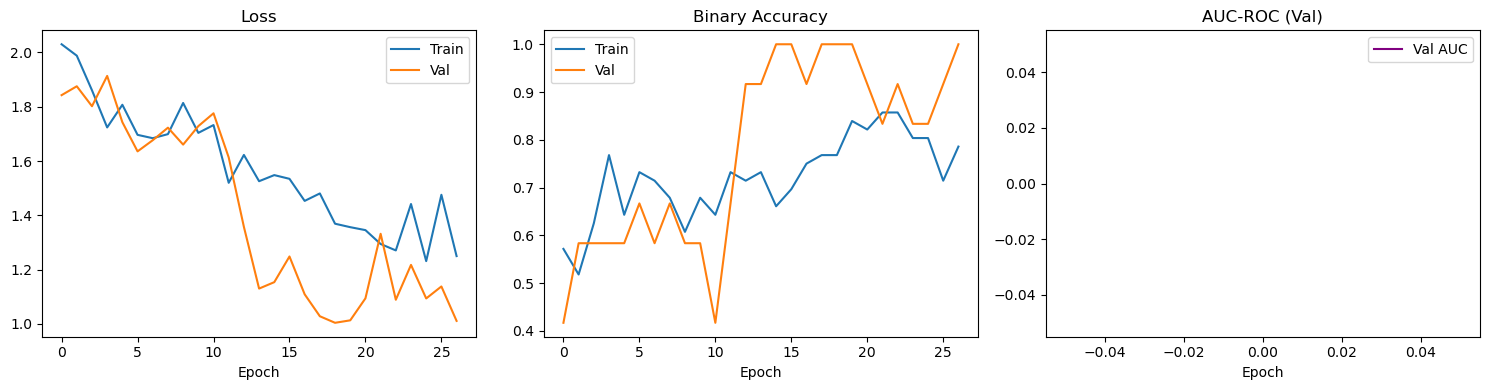

Saved: plots/training_curves.png


In [16]:
def plot_curves(history, save_path='plots/training_curves.png'):
    fig, axes = plt.subplots(1, 3, figsize=(15, 4))

    axes[0].plot(history['train_loss'], label='Train')
    axes[0].plot(history['val_loss'],   label='Val')
    axes[0].set_title('Loss'); axes[0].set_xlabel('Epoch')
    axes[0].legend()

    axes[1].plot(history['train_acc'], label='Train')
    axes[1].plot(history['val_acc'],   label='Val')
    axes[1].set_title('Binary Accuracy'); axes[1].set_xlabel('Epoch')
    axes[1].legend()

    axes[2].plot(history['val_auc'], color='purple', label='Val AUC')
    axes[2].set_title('AUC-ROC (Val)'); axes[2].set_xlabel('Epoch')
    axes[2].legend()

    plt.tight_layout()
    plt.savefig(save_path, dpi=150)
    plt.show()
    print(f'Saved: {save_path}')

plot_curves(history)

## 6. Test-Set Evaluation

In [17]:
# Load best checkpoint
model.load_state_dict(torch.load('checkpoints/best_model.pth', map_location=device))

(test_loss, test_acc, test_sub_acc, test_auc,
 test_preds, test_labels,
 test_sub_preds, test_sub_labels,
 test_unc, test_probs) = eval_epoch(model, test_loader, criterion, device)

precision = precision_score(test_labels, test_preds, average='weighted', zero_division=0)
recall    = recall_score(test_labels, test_preds, average='weighted', zero_division=0)
f1        = f1_score(test_labels, test_preds, average='weighted', zero_division=0)

print('='*55)
print(f'Test Accuracy  (binary) : {test_acc:.4f}')
print(f'Test Accuracy  (subtype): {test_sub_acc:.4f}')
print(f'Test AUC-ROC            : {test_auc:.4f}')
print(f'Test Precision          : {precision:.4f}')
print(f'Test Recall             : {recall:.4f}')
print(f'Test F1                 : {f1:.4f}')
print('='*55)

print('\nClassification Report:')
print(classification_report(test_labels, test_preds,
                             target_names=['Benign', 'Malignant']))

Test Accuracy  (binary) : 0.6923
Test Accuracy  (subtype): 0.3077
Test AUC-ROC            : 0.6667
Test Precision          : 0.7051
Test Recall             : 0.6923
Test F1                 : 0.6808

Classification Report:
              precision    recall  f1-score   support

      Benign       0.75      0.50      0.60         6
   Malignant       0.67      0.86      0.75         7

    accuracy                           0.69        13
   macro avg       0.71      0.68      0.68        13
weighted avg       0.71      0.69      0.68        13



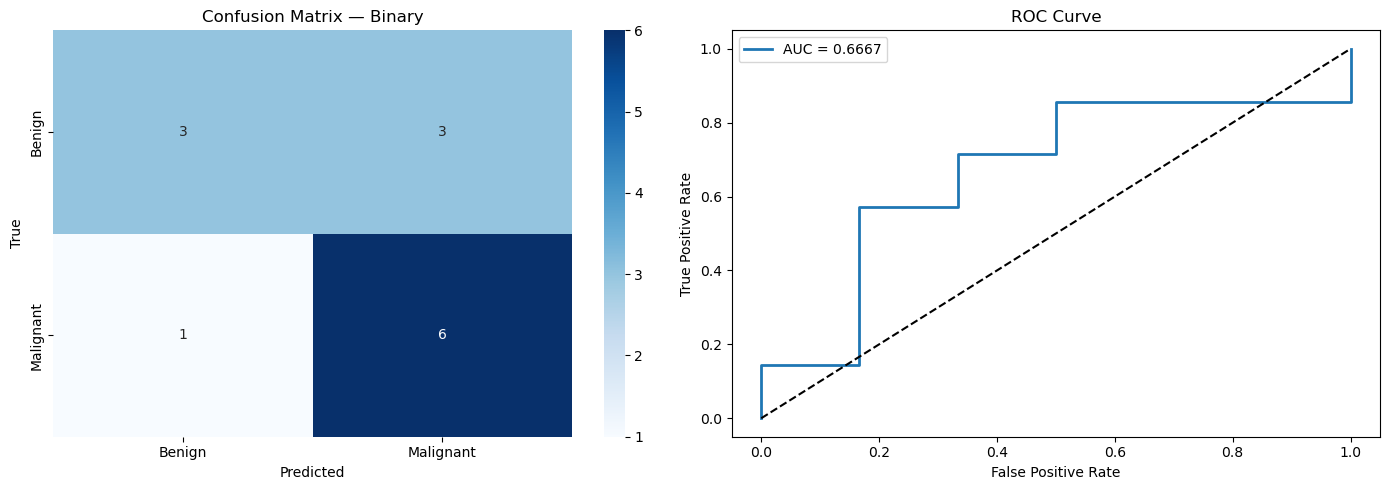

In [18]:
# ── Confusion matrix ──────────────────────────────────────────────────────────
cm = confusion_matrix(test_labels, test_preds)
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', ax=axes[0],
            xticklabels=['Benign','Malignant'],
            yticklabels=['Benign','Malignant'])
axes[0].set_title('Confusion Matrix — Binary')
axes[0].set_xlabel('Predicted'); axes[0].set_ylabel('True')

# ROC curve
fpr, tpr, _ = roc_curve(test_labels, test_probs)
axes[1].plot(fpr, tpr, lw=2, label=f'AUC = {test_auc:.4f}')
axes[1].plot([0,1],[0,1],'k--')
axes[1].set_xlabel('False Positive Rate'); axes[1].set_ylabel('True Positive Rate')
axes[1].set_title('ROC Curve')
axes[1].legend()

plt.tight_layout()
plt.savefig('plots/evaluation.png', dpi=150)
plt.show()

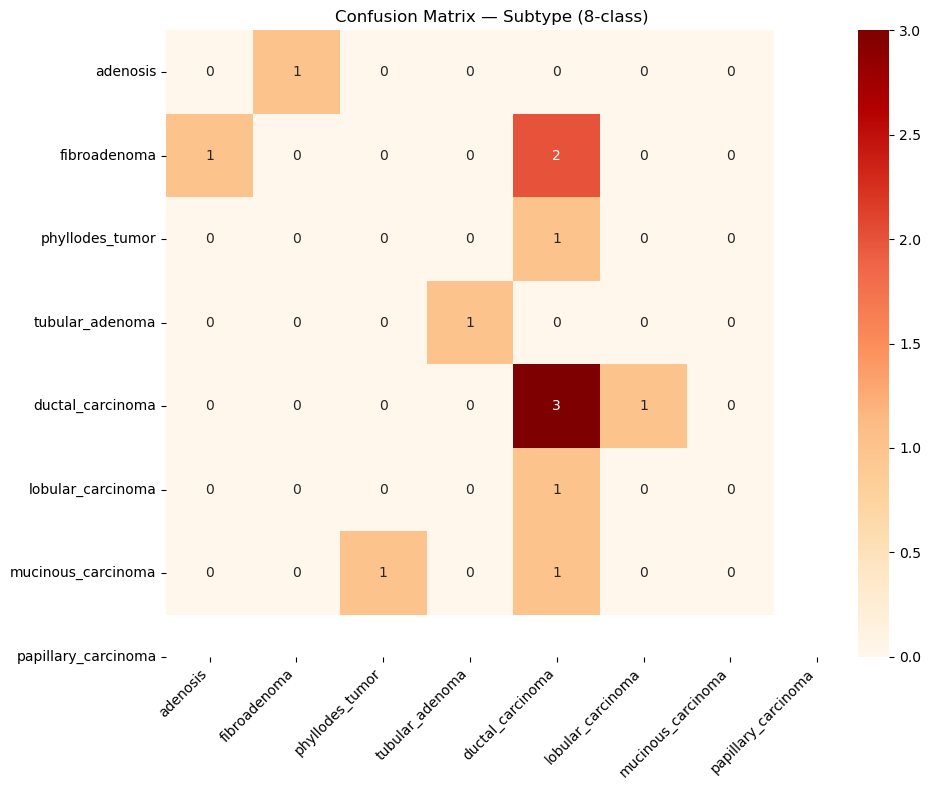

In [19]:
# Subtype confusion matrix (8-class)
if len(set(test_sub_labels)) > 1:
    cm_sub = confusion_matrix(test_sub_labels, test_sub_preds)
    plt.figure(figsize=(10, 8))
    sns.heatmap(cm_sub, annot=True, fmt='d', cmap='OrRd',
                xticklabels=ALL_SUBS, yticklabels=ALL_SUBS)
    plt.xticks(rotation=45, ha='right')
    plt.yticks(rotation=0)
    plt.title('Confusion Matrix — Subtype (8-class)')
    plt.tight_layout()
    plt.savefig('plots/confusion_subtype.png', dpi=150)
    plt.show()

## 7. Ablation Studies

In [21]:
ABLATION_EPOCHS    = 20     # shorter runs for ablation
ABLATION_PATIENCE  = 8

def _safe_name(config_name):
    """Sanitise config name for use as a filename (remove / \ : * ? etc.)"""
    import re
    return re.sub(r'[^\w\-]', '_', config_name)


def run_ablation(config_name, use_gnn=True, use_aux=True, use_attn=True):
    """
    Train a model variant and evaluate on the test set.
    use_attn=False replaces CrossMagFusion with simple mean pooling.
    """
    print(f'\n── Ablation: {config_name} ──────────────────────────────────────')
    torch.cuda.empty_cache()

    m = MAGNET(feat_dim=FEAT_DIM, pretrained=True,
               use_gnn=use_gnn, use_aux=use_aux).to(device)

    if not use_attn:
        def mean_forward(self, feats):
            x = torch.stack(feats, dim=1)          # [B, 4, D]
            dummy_attn = torch.zeros(x.size(0), 4, 4, device=x.device)
            return x.mean(dim=1), dummy_attn
        import types
        m.fusion.forward = types.MethodType(mean_forward, m.fusion)

    bb_p = [p for n, p in m.named_parameters()
            if any(n.startswith(f'branches.{mg}.backbone') for mg in MAGNIFICATIONS)]
    oth  = [p for n, p in m.named_parameters()
            if not any(n.startswith(f'branches.{mg}.backbone') for mg in MAGNIFICATIONS)]

    opt  = optim.AdamW([{'params': bb_p, 'lr': LR * 0.1},
                        {'params': oth,  'lr': LR}],
                       weight_decay=WEIGHT_DECAY)
    sch  = optim.lr_scheduler.CosineAnnealingLR(opt, T_max=ABLATION_EPOCHS)
    crit = MAGNETLoss(gamma=0.3 if use_aux else 0.0)

    # GradScaler — compatible with PyTorch <2.4 and >=2.4
    try:
        sc = torch.amp.GradScaler(device='cuda')
    except TypeError:
        sc = torch.cuda.amp.GradScaler()

    best_acc  = 0.0
    pat       = 0
    # FIX: sanitise config_name → safe filename (removes '/' '\\' etc.)
    safe      = _safe_name(config_name)
    ckpt_dir  = 'checkpoints'
    os.makedirs(ckpt_dir, exist_ok=True)
    ckpt_path = os.path.join(ckpt_dir, f'ablation_{safe}.pth')

    for ep in range(1, ABLATION_EPOCHS + 1):
        train_epoch(m, train_loader, opt, crit, sc, device)
        vl, va, *_ = eval_epoch(m, val_loader, crit, device)
        sch.step()
        if va > best_acc:
            best_acc = va
            torch.save(m.state_dict(), ckpt_path)
            pat = 0
        else:
            pat += 1
            if pat >= ABLATION_PATIENCE:
                print(f'  Early stop at ep{ep}')
                break
        print(f'  ep{ep:02d}: val_acc={va:.4f}')

    m.load_state_dict(torch.load(ckpt_path, map_location=device))
    _, ta, tsa, taucroc, *_ = eval_epoch(m, test_loader, crit, device)
    del m
    torch.cuda.empty_cache()
    print(f'  → test_acc={ta:.4f}  sub_acc={tsa:.4f}  auc={taucroc:.4f}')
    return {'config': config_name, 'val_acc': best_acc,
            'test_acc': ta, 'sub_acc': tsa, 'auc': taucroc}


ablation_rows = []

# Full model result (already computed above)
ablation_rows.append({
    'config'  : 'MAGNET (full)',
    'val_acc' : best_val_acc,
    'test_acc': test_acc,
    'sub_acc' : test_sub_acc,
    'auc'     : test_auc,
})

ablation_rows.append(run_ablation('wo_GNN',  use_gnn=False, use_aux=True,  use_attn=True))
ablation_rows.append(run_ablation('wo_Aux',  use_gnn=True,  use_aux=False, use_attn=True))
ablation_rows.append(run_ablation('wo_Attn', use_gnn=True,  use_aux=True,  use_attn=False))
ablation_rows.append(run_ablation('wo_Both', use_gnn=False, use_aux=False, use_attn=False))

# Restore display-friendly labels for the table/chart
label_map = {
    'wo_GNN' : 'w/o GNN',
    'wo_Aux' : 'w/o Aux',
    'wo_Attn': 'w/o Attn',
    'wo_Both': 'w/o Both',
}
for row in ablation_rows:
    row['config'] = label_map.get(row['config'], row['config'])

ablation_df = pd.DataFrame(ablation_rows)
ablation_df.to_csv('results/ablation_results.csv', index=False)
print('\n' + ablation_df.to_string(index=False))



── Ablation: wo_GNN ──────────────────────────────────────


  ep01: val_acc=0.6667


  ep02: val_acc=0.5000


  ep03: val_acc=0.8333


  ep04: val_acc=0.5833


  ep05: val_acc=0.5833


... (46 outputs left out)

  ep07: val_acc=0.9167


  ep08: val_acc=1.0000


  Early stop at ep9


  → test_acc=0.5385  sub_acc=0.0000  auc=0.5476

       config  val_acc  test_acc  sub_acc      auc
MAGNET (full) 1.000000  0.692308 0.307692 0.666667
      w/o GNN 1.000000  0.692308 0.230769 0.761905
      w/o Aux 1.000000  0.769231 0.461538 0.714286
     w/o Attn 0.916667  0.615385 0.230769 0.595238
     w/o Both 1.000000  0.538462 0.000000 0.547619


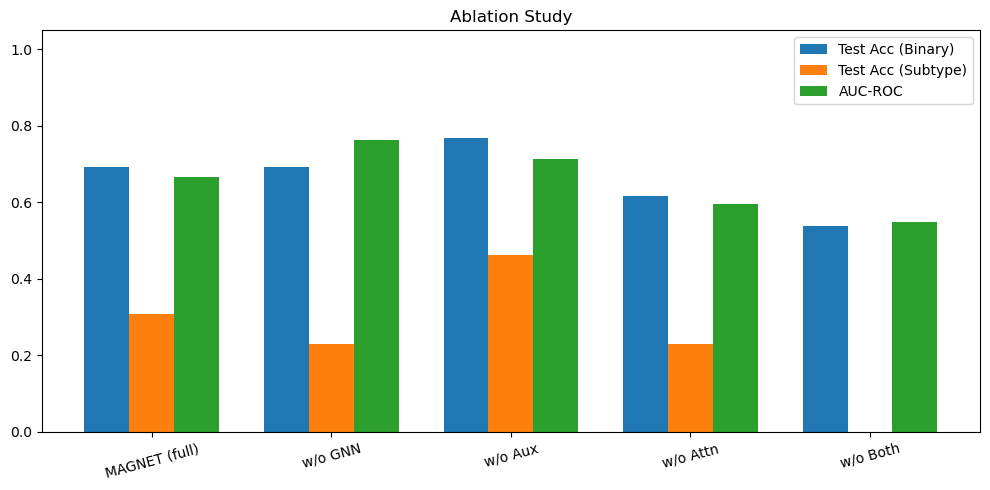

In [22]:
# ── Ablation bar chart ────────────────────────────────────────────────────────
fig, ax = plt.subplots(figsize=(10, 5))
x = range(len(ablation_df))
width = 0.25
ax.bar([i - width for i in x], ablation_df['test_acc'],  width, label='Test Acc (Binary)')
ax.bar([i         for i in x], ablation_df['sub_acc'],   width, label='Test Acc (Subtype)')
ax.bar([i + width for i in x], ablation_df['auc'],       width, label='AUC-ROC')
ax.set_xticks(list(x))
ax.set_xticklabels(ablation_df['config'], rotation=15)
ax.set_ylim(0, 1.05)
ax.legend()
ax.set_title('Ablation Study')
plt.tight_layout()
plt.savefig('plots/ablation.png', dpi=150)
plt.show()

## 8. Baseline Comparisons

In [23]:
# ── Single-backbone baseline at each magnification ────────────────────────────
class SingleMagDataset(Dataset):
    """Single-magnification version of MultiMagDataset."""
    def __init__(self, patient_ids, patient_info, mag, transform=None,
                 stain_norm=True, img_size=224, synthetic=False):
        self.patient_ids  = patient_ids
        self.patient_info = patient_info
        self.mag          = mag
        self.transform    = transform
        self.stain_norm   = stain_norm
        self.img_size     = img_size
        self.synthetic    = synthetic

    def __len__(self):
        return len(self.patient_ids)

    def _load(self, path):
        if self.synthetic or path is None:
            return torch.randn(3, self.img_size, self.img_size)
        img = Image.open(path).convert('RGB').resize(
            (self.img_size, self.img_size), Image.BILINEAR)
        if self.stain_norm:
            img = macenko_norm(img)
        if self.transform:
            img = self.transform(img)
        return img

    def __getitem__(self, idx):
        pid  = self.patient_ids[idx]
        info = self.patient_info[pid]
        paths = info['paths'][self.mag]
        path  = random.choice(paths) if paths else None
        return self._load(path), int(info['binary'])


def train_baseline(backbone_name, out_dim, mag, epochs=20, patience=6):
    """
    Single backbone, single magnification baseline.
    Returns test accuracy and AUC.
    """
    print(f'\n── Baseline: {backbone_name} @ {mag} ────────────────────────────')
    torch.cuda.empty_cache()

    def make_single_loader(patients, tf, shuffle):
        ds = SingleMagDataset(patients, patient_info, mag, transform=tf,
                              stain_norm=(not SYNTHETIC), img_size=IMG_SIZE,
                              synthetic=SYNTHETIC)
        return DataLoader(ds, batch_size=BATCH_SIZE * 2, shuffle=shuffle,
                          num_workers=NUM_WORKERS, pin_memory=True, drop_last=shuffle)

    tl = make_single_loader(train_patients, train_tf, True)
    vl = make_single_loader(val_patients,   val_tf,   False)
    el = make_single_loader(test_patients,  val_tf,   False)

    m   = timm.create_model(backbone_name, pretrained=True,
                             num_classes=2, global_pool='avg').to(device)
    opt = optim.AdamW(m.parameters(), lr=LR, weight_decay=WEIGHT_DECAY)
    sch = optim.lr_scheduler.CosineAnnealingLR(opt, T_max=epochs)
    ce  = nn.CrossEntropyLoss()
    sc  = GradScaler()

    best_acc = 0.0; pat = 0
    ckpt = f'checkpoints/baseline_{backbone_name}_{mag}.pth'

    for ep in range(1, epochs + 1):
        m.train()
        for imgs, labels in tl:
            imgs, labels = imgs.to(device), labels.to(device)
            opt.zero_grad()
            with autocast():
                loss = ce(m(imgs), labels)
            sc.scale(loss).backward(); sc.step(opt); sc.update()
        sch.step()

        m.eval(); preds, labs = [], []
        with torch.no_grad():
            for imgs, labels in vl:
                preds.extend(m(imgs.to(device)).argmax(1).cpu().tolist())
                labs.extend(labels.tolist())
        va = accuracy_score(labs, preds)
        if va > best_acc:
            best_acc = va; torch.save(m.state_dict(), ckpt); pat = 0
        else:
            pat += 1
            if pat >= patience: break
        print(f'  ep{ep:02d}: val_acc={va:.4f}')

    m.load_state_dict(torch.load(ckpt, map_location=device))
    m.eval(); preds, labs, probs = [], [], []
    with torch.no_grad():
        for imgs, labels in el:
            logits = m(imgs.to(device))
            preds.extend(logits.argmax(1).cpu().tolist())
            probs.extend(F.softmax(logits, dim=1)[:, 1].cpu().tolist())
            labs.extend(labels.tolist())
    ta = accuracy_score(labs, preds)
    try:
        ta_auc = roc_auc_score(labs, probs)
    except ValueError:
        ta_auc = float('nan')
    print(f'  → test_acc={ta:.4f}  auc={ta_auc:.4f}')
    return {'config': f'{backbone_name}@{mag}', 'test_acc': ta, 'auc': ta_auc}


baseline_rows = []
baselines = [
    ('resnet34',           512,  '40X'),
    ('efficientnet_b0',    1280, '40X'),
    ('mobilenetv3_large_100', 960, '40X'),
    ('resnet34',           512,  '200X'),
]
for bn, od, mag in baselines:
    row = train_baseline(bn, od, mag)
    baseline_rows.append(row)

# Add MAGNET result
baseline_rows.append({'config': 'MAGNET (ours)', 'test_acc': test_acc, 'auc': test_auc})

baseline_df = pd.DataFrame(baseline_rows)
baseline_df.to_csv('results/baseline_comparison.csv', index=False)
print('\n' + baseline_df.to_string(index=False))


── Baseline: resnet34 @ 40X ────────────────────────────
  ep01: val_acc=0.1667
  ep02: val_acc=0.5000
  ep03: val_acc=0.6667
  ep04: val_acc=0.9167
  ep05: val_acc=1.0000
  ep06: val_acc=1.0000
  ep07: val_acc=1.0000
  ep08: val_acc=1.0000
  ep09: val_acc=1.0000
  ep10: val_acc=1.0000
  → test_acc=0.5385  auc=0.2381

── Baseline: efficientnet_b0 @ 40X ────────────────────────────
  ep01: val_acc=0.7500
  ep02: val_acc=0.6667
  ep03: val_acc=0.8333
  ep04: val_acc=0.5833
  ep05: val_acc=0.7500
  ep06: val_acc=0.6667
  ep07: val_acc=0.8333
  ep08: val_acc=0.6667
  → test_acc=0.6154  auc=0.6190

── Baseline: mobilenetv3_large_100 @ 40X ────────────────────────────
  ep01: val_acc=0.7500
  ep02: val_acc=0.2500
  ep03: val_acc=0.5833
  ep04: val_acc=0.5833
  ep05: val_acc=0.7500
  ep06: val_acc=0.9167
  ep07: val_acc=0.8333
  ep08: val_acc=0.6667
  ep09: val_acc=0.6667
  ep10: val_acc=0.7500
  ep11: val_acc=0.5833
  → test_acc=0.5385  auc=0.5952

── Baseline: resnet34 @ 200X ─────────────

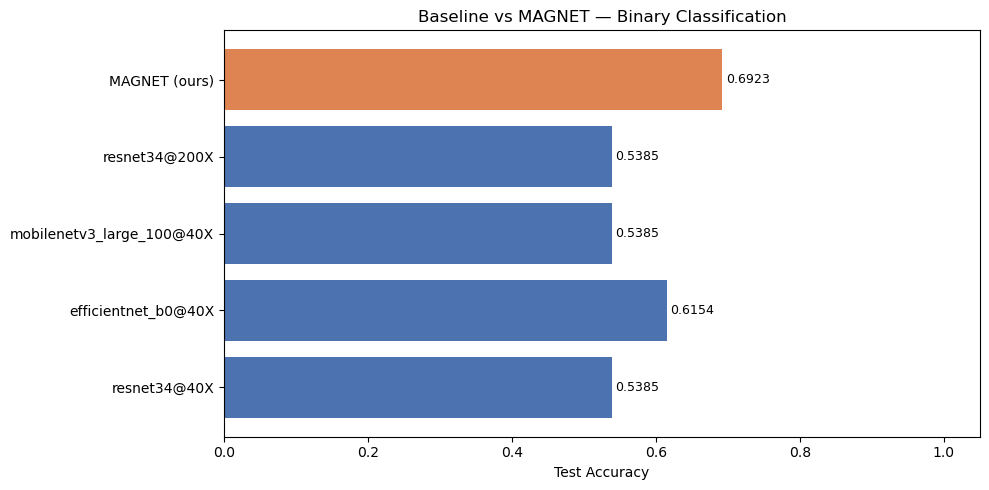

In [24]:
# ── Comparison chart ──────────────────────────────────────────────────────────
fig, ax = plt.subplots(figsize=(10, 5))
colors = ['#4C72B0'] * (len(baseline_df) - 1) + ['#DD8452']  # highlight MAGNET
bars = ax.barh(baseline_df['config'], baseline_df['test_acc'], color=colors)
ax.set_xlabel('Test Accuracy')
ax.set_title('Baseline vs MAGNET — Binary Classification')
ax.set_xlim(0, 1.05)
for bar, val in zip(bars, baseline_df['test_acc']):
    ax.text(bar.get_width() + 0.005, bar.get_y() + bar.get_height() / 2,
            f'{val:.4f}', va='center', fontsize=9)
plt.tight_layout()
plt.savefig('plots/baseline_comparison.png', dpi=150)
plt.show()

## 9. Interpretability

### 9.1 Attention Weight Visualisation

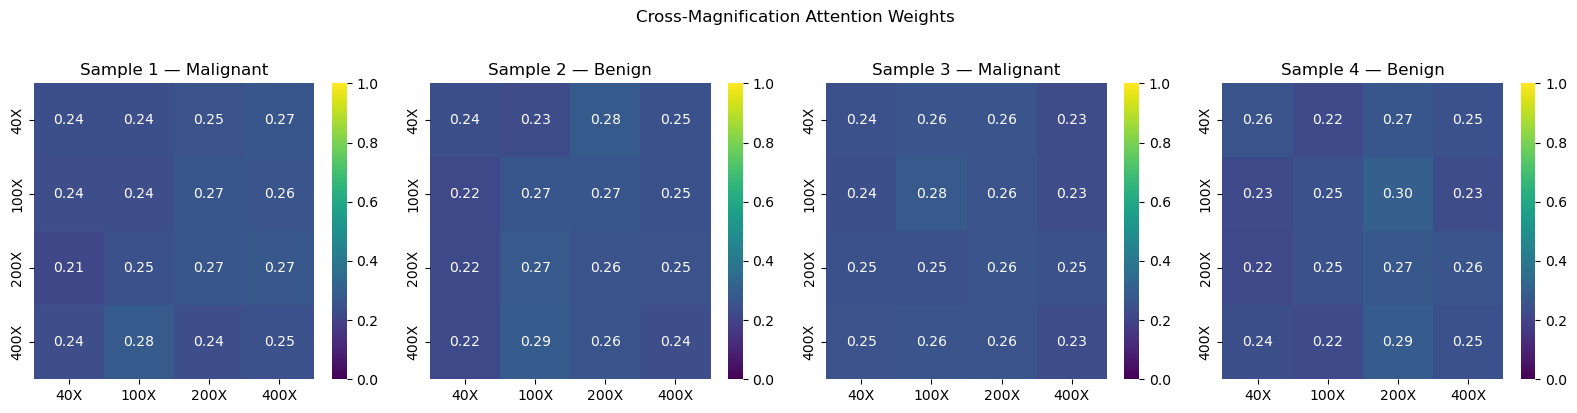

In [25]:
model.load_state_dict(torch.load('checkpoints/best_model.pth', map_location=device))
model.eval()

def plot_attention_weights(model, loader, device, n_samples=4):
    batch = next(iter(loader))
    x40, x100, x200, x400, y_bin, y_sub = [b.to(device) for b in batch]
    x40, x100, x200, x400 = x40[:n_samples], x100[:n_samples], x200[:n_samples], x400[:n_samples]
    y_bin = y_bin[:n_samples]

    with torch.no_grad(), autocast():
        *_, attn_w = model(x40, x100, x200, x400, return_attn=True)  # [B, 4, 4]

    fig, axes = plt.subplots(1, n_samples, figsize=(4 * n_samples, 4))
    if n_samples == 1:
        axes = [axes]
    labels_str = ['Benign', 'Malignant']

    for i, ax in enumerate(axes):
        w = attn_w[i].cpu().float().numpy()
        sns.heatmap(w, annot=True, fmt='.2f', cmap='viridis', ax=ax,
                    xticklabels=MAGNIFICATIONS,
                    yticklabels=MAGNIFICATIONS, vmin=0, vmax=1)
        ax.set_title(f'Sample {i+1} — {labels_str[y_bin[i].item()]}')

    plt.suptitle('Cross-Magnification Attention Weights', y=1.02)
    plt.tight_layout()
    plt.savefig('plots/attention_weights.png', dpi=150, bbox_inches='tight')
    plt.show()

plot_attention_weights(model, test_loader, device)

### 9.2 Grad-CAM per Backbone Branch

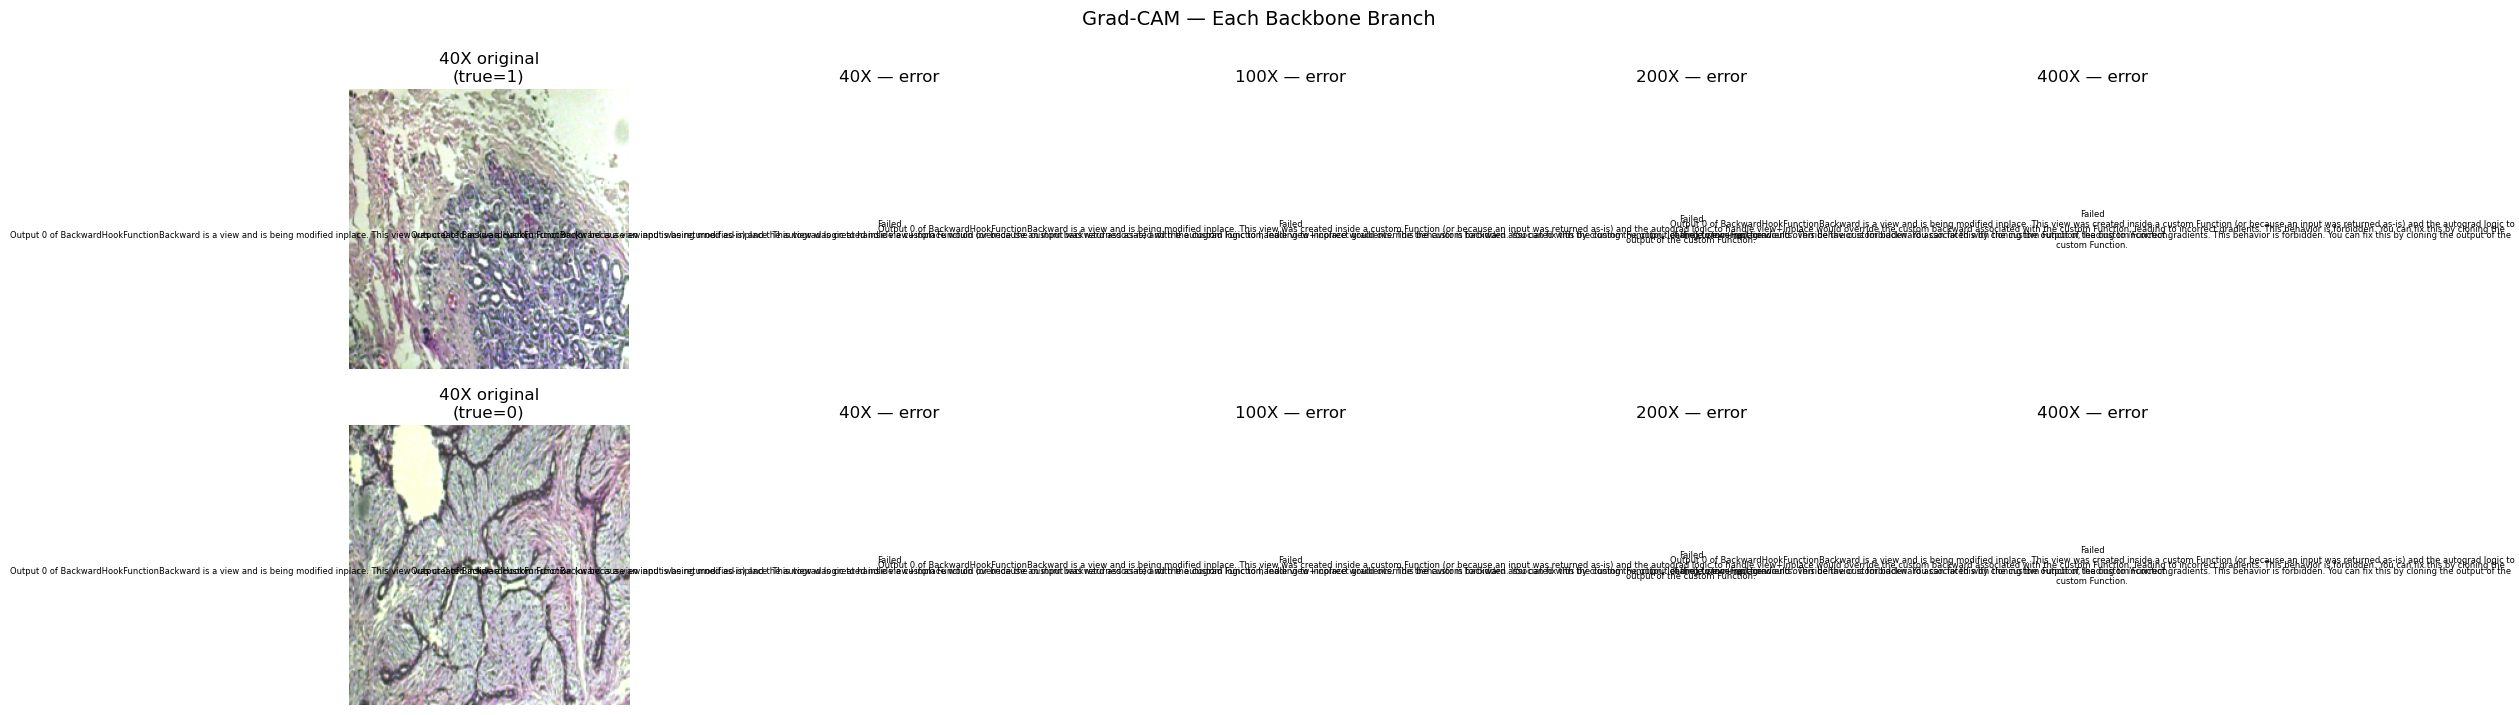

Saved: plots/gradcam.png


MAGNET(
  (branches): ModuleDict(
    (40X): BranchExtractor(
      (backbone): MobileNetV3(
        (conv_stem): Conv2d(3, 16, kernel_size=(3, 3), stride=(2, 2), padding=(1, 1), bias=False)
        (bn1): BatchNormAct2d(
          16, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True
          (drop): Identity()
          (act): Hardswish()
        )
        (blocks): Sequential(
          (0): Sequential(
            (0): DepthwiseSeparableConv(
              (conv_dw): Conv2d(16, 16, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1), groups=16, bias=False)
              (bn1): BatchNormAct2d(
                16, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True
                (drop): Identity()
                (act): ReLU(inplace=True)
              )
              (aa): Identity()
              (se): Identity()
              (conv_pw): Conv2d(16, 16, kernel_size=(1, 1), stride=(1, 1), bias=False)
              (bn2): BatchNormAct2d(
                16, ep

In [28]:
class GradCAM:
    """
    Grad-CAM fixed for MobileNetV3/EfficientNet inplace Hardswish/SiLU.
    Hooks on the last feature-map conv BEFORE any inplace activation head.
    Clones both activation and gradient to prevent view-inplace conflicts.
    """

    def __init__(self, model, target_layer: nn.Module):
        self.model       = model
        self.activations = None
        self.gradients   = None
        self._fwd = target_layer.register_forward_hook(self._save_act)
        self._bwd = target_layer.register_full_backward_hook(self._save_grad)

    def _save_act(self, module, inp, out):
        self.activations = out.detach().clone()   # clone breaks the inplace view

    def _save_grad(self, module, grad_in, grad_out):
        self.gradients = grad_out[0].detach().clone()

    def __call__(self, x40, x100, x200, x400, class_idx=None):
        self.model.zero_grad()
        bl, sl, unc, aux = self.model(x40, x100, x200, x400)
        if class_idx is None:
            class_idx = bl.argmax(dim=1)[0].item()
        bl[0, class_idx].backward()

        alpha = self.gradients.mean(dim=(2, 3), keepdim=True)   # [1, C, 1, 1]
        cam   = (alpha * self.activations).sum(dim=1, keepdim=True)
        cam   = F.relu(cam)
        cam   = F.interpolate(cam, size=(224, 224), mode='bilinear', align_corners=False)
        cam   = cam.squeeze().cpu().float().numpy()
        if cam.max() > 0:
            cam = cam / cam.max()
        return cam, class_idx

    def remove_hooks(self):
        self._fwd.remove()
        self._bwd.remove()


def get_gradcam_layer(branch_extractor, mag):
    """
    Returns the last safe Conv2d for Grad-CAM — one that is NOT
    followed by an inplace activation (Hardswish_, SiLU_, ReLU_).

    Strategy per backbone (confirmed from printed architecture):
      MobileNetV3 (40X, 400X): last conv_pwl in backbone.blocks[-1][-1]
      EfficientNet-B0 (100X):   last conv_pwl in backbone.blocks[-1][-1]
      ResNet34 (200X):           backbone.layer4[-1].conv2
    """
    backbone = branch_extractor.backbone

    # ResNet: layer4[-1].conv2 is followed by BatchNorm + non-inplace act2
    if hasattr(backbone, 'layer4'):
        return backbone.layer4[-1].conv2

    # MobileNetV3 / EfficientNet: walk blocks[-1][-1] for conv_pwl
    if hasattr(backbone, 'blocks'):
        last_stage = backbone.blocks[-1]
        # last_stage is a Sequential; get its last child
        last_block = list(last_stage.children())[-1]
        # InvertedResidual / DepthwiseSeparableConv / ConvBnAct
        for attr in ['conv_pwl', 'conv_pw', 'conv']:
            layer = getattr(last_block, attr, None)
            if isinstance(layer, nn.Conv2d):
                return layer

    # Hard fallback: second-to-last Conv2d in the whole backbone
    # (avoids conv_head which feeds into inplace Hardswish)
    all_convs = [m for m in backbone.modules() if isinstance(m, nn.Conv2d)]
    if len(all_convs) >= 2:
        return all_convs[-2]   # skip conv_head
    return all_convs[-1] if all_convs else None


def show_gradcam(model, loader, device, save_path='plots/gradcam.png', n_samples=2):
    if SYNTHETIC:
        print('[SYNTHETIC mode] Grad-CAM skipped.')
        return

    model.eval()
    batch = next(iter(loader))
    x40, x100, x200, x400, y_bin, _ = [b.to(device) for b in batch]
    inputs = {
        '40X' : x40[:n_samples],
        '100X': x100[:n_samples],
        '200X': x200[:n_samples],
        '400X': x400[:n_samples],
    }

    inv_mean = [-m/s for m, s in zip(mean, std)]
    inv_std  = [1/s  for s in std]
    denorm   = transforms.Normalize(inv_mean, inv_std)

    fig, axes = plt.subplots(n_samples, len(MAGNIFICATIONS) + 1,
                              figsize=(5 * (len(MAGNIFICATIONS) + 1), 4 * n_samples))
    if n_samples == 1:
        axes = [axes]

    for sample_i in range(n_samples):
        row = axes[sample_i]

        img40 = denorm(x40[sample_i].cpu()).permute(1, 2, 0).clamp(0, 1).numpy()
        row[0].imshow(img40)
        row[0].set_title(f'40X original\n(true={y_bin[sample_i].item()})')
        row[0].axis('off')

        for col_j, mag in enumerate(MAGNIFICATIONS, start=1):
            target_layer = get_gradcam_layer(model.branches[mag], mag)

            if target_layer is None:
                row[col_j].text(0.5, 0.5, 'No layer', ha='center', va='center')
                row[col_j].axis('off')
                continue

            single = {m: inputs[m][sample_i:sample_i+1] for m in MAGNIFICATIONS}

            model.train()   # keeps dropout, enables grad hooks
            cam_gen = GradCAM(model, target_layer)
            try:
                cam, pred = cam_gen(
                    single['40X'], single['100X'],
                    single['200X'], single['400X']
                )
                img_m   = denorm(inputs[mag][sample_i].cpu()).permute(1, 2, 0).clamp(0, 1).numpy()
                overlay = cv2.applyColorMap((cam * 255).astype(np.uint8), cv2.COLORMAP_JET)
                overlay = cv2.cvtColor(overlay, cv2.COLOR_BGR2RGB) / 255.0
                blended = (0.5 * img_m + 0.5 * overlay).clip(0, 1)
                row[col_j].imshow(blended)
                row[col_j].set_title(f'{mag} Grad-CAM\n(pred={pred})')
            except Exception as e:
                row[col_j].text(0.5, 0.5, f'Failed\n{e}', ha='center', va='center',
                                fontsize=6, wrap=True)
                row[col_j].set_title(f'{mag} — error')
            finally:
                cam_gen.remove_hooks()
                model.eval()

            row[col_j].axis('off')

    plt.suptitle('Grad-CAM — Each Backbone Branch', fontsize=14)
    plt.tight_layout()
    plt.savefig(save_path, dpi=150, bbox_inches='tight')
    plt.show()
    print(f'Saved: {save_path}')


model.train()
show_gradcam(model, test_loader, device)
model.eval()

### 9.3 Monte-Carlo Dropout Uncertainty Analysis

  Skipping batch 3 (size=1, BN requires ≥2 samples)
MC-Dropout (20 passes) on 12 samples:
  Mean uncertainty (correct)  : 0.0035
  Mean uncertainty (incorrect): 0.0082


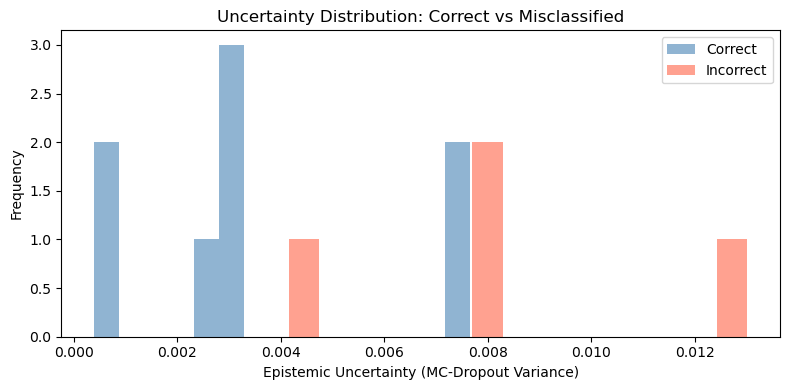

In [30]:
def mc_uncertainty_analysis(model, loader, device, n_passes=20, max_batches=5):
    all_means, all_vars, all_labels, all_preds = [], [], [], []

    for i, batch in enumerate(loader):
        if i >= max_batches:
            break
        x40, x100, x200, x400, y_bin, _ = [b.to(device) for b in batch]

        # Skip singleton batches — BN still fails during backbone forward even in eval
        # mc_uncertainty handles BN internally but backbone BN2d also needs >1 sample
        if x40.shape[0] < 2:
            print(f'  Skipping batch {i} (size=1, BN requires ≥2 samples)')
            continue

        mean_p, var_p = model.mc_uncertainty(x40, x100, x200, x400, n_passes)
        all_means.append(mean_p.cpu())
        all_vars.append(var_p.cpu())
        all_labels.extend(y_bin.cpu().tolist())
        all_preds.extend(mean_p.argmax(1).cpu().tolist())

    if not all_means:
        print('No valid batches for MC uncertainty analysis.')
        return np.array([]), np.array([])

    all_means  = torch.cat(all_means, dim=0)
    all_vars   = torch.cat(all_vars,  dim=0)
    unc_scores = all_vars.mean(dim=1).numpy()
    correct    = np.array(all_labels) == np.array(all_preds)

    print(f'MC-Dropout ({n_passes} passes) on {len(all_labels)} samples:')
    if correct.sum() > 0:
        print(f'  Mean uncertainty (correct)  : {unc_scores[correct].mean():.4f}')
    if (~correct).sum() > 0:
        print(f'  Mean uncertainty (incorrect): {unc_scores[~correct].mean():.4f}')

    plt.figure(figsize=(8, 4))
    if correct.sum() > 0:
        plt.hist(unc_scores[correct],  bins=15, alpha=0.6, label='Correct',    color='steelblue')
    if (~correct).sum() > 0:
        plt.hist(unc_scores[~correct], bins=15, alpha=0.6, label='Incorrect',  color='tomato')
    plt.xlabel('Epistemic Uncertainty (MC-Dropout Variance)')
    plt.ylabel('Frequency')
    plt.title('Uncertainty Distribution: Correct vs Misclassified')
    plt.legend()
    plt.tight_layout()
    plt.savefig('plots/mc_uncertainty.png', dpi=150)
    plt.show()

    return unc_scores, correct

unc_scores, correct = mc_uncertainty_analysis(model, test_loader, device)

## 10. Per-Magnification Accuracy Analysis

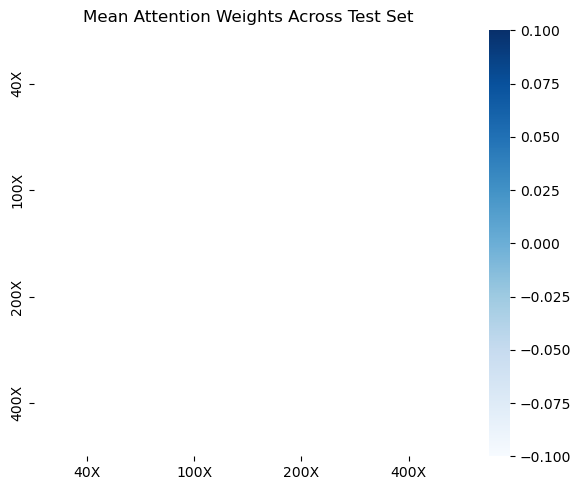

Diagonal attention weights (self-contribution per magnification):
  40X: nan
  100X: nan
  200X: nan
  400X: nan


In [31]:
# Evaluate attention weight distribution per magnification
# — tells us which magnification the model relies on most

model.eval()
all_attn = []
with torch.no_grad(), autocast():
    for batch in tqdm(test_loader, desc='Collecting attention'):
        x40, x100, x200, x400, y_bin, _ = [b.to(device) for b in batch]
        *_, attn_w = model(x40, x100, x200, x400, return_attn=True)  # [B, 4, 4]
        all_attn.append(attn_w.cpu().float())

all_attn = torch.cat(all_attn, dim=0)   # [N, 4, 4]
mean_attn = all_attn.mean(0).numpy()    # [4, 4]

plt.figure(figsize=(6, 5))
sns.heatmap(mean_attn, annot=True, fmt='.3f', cmap='Blues',
            xticklabels=MAGNIFICATIONS, yticklabels=MAGNIFICATIONS)
plt.title('Mean Attention Weights Across Test Set')
plt.tight_layout()
plt.savefig('plots/mean_attention.png', dpi=150)
plt.show()

# Per-magnification self-attention (diagonal = self-weight)
diag_weights = np.diag(mean_attn)
print('Diagonal attention weights (self-contribution per magnification):')
for mag, w in zip(MAGNIFICATIONS, diag_weights):
    print(f'  {mag}: {w:.4f}')

## 11. Save All Results

In [32]:
final_results = {
    'model_params_M': round(sum(p.numel() for p in model.parameters()) / 1e6, 2),
    'test_metrics': {
        'accuracy_binary' : round(test_acc,     4),
        'accuracy_subtype': round(test_sub_acc, 4),
        'auc_roc'         : round(test_auc,     4),
        'precision'       : round(precision,    4),
        'recall'          : round(recall,       4),
        'f1'              : round(f1,           4),
        'loss'            : round(test_loss,    4),
    },
    'best_val_acc'  : round(best_val_acc, 4),
    'ablation'      : ablation_df.to_dict(orient='records'),
    'baselines'     : baseline_df.to_dict(orient='records'),
    'training_history': history,
    'confusion_matrix': cm.tolist(),
    'mean_attn_weights': mean_attn.tolist(),
}

with open('results/all_results.json', 'w') as f:
    json.dump(final_results, f, indent=2)

# Metrics table for paper
metrics_df = pd.DataFrame([final_results['test_metrics']])
metrics_df.to_csv('results/test_metrics.csv', index=False)

# Full classification report
report_df = pd.DataFrame(
    classification_report(test_labels, test_preds,
                          target_names=['Benign', 'Malignant'],
                          output_dict=True)
).transpose()
report_df.to_csv('results/classification_report.csv')

print('All results saved to results/')
print('All plots  saved to plots/')
print('Best model saved to checkpoints/best_model.pth')
print('\n── Final Results ──────────────────────────────────────────')
for k, v in final_results['test_metrics'].items():
    print(f'  {k:<22}: {v}')

All results saved to results/
All plots  saved to plots/
Best model saved to checkpoints/best_model.pth

── Final Results ──────────────────────────────────────────
  accuracy_binary       : 0.6923
  accuracy_subtype      : 0.3077
  auc_roc               : 0.6667
  precision             : 0.7051
  recall                : 0.6923
  f1                    : 0.6808
  loss                  : 2.0678


## 12. Paper-Ready Summary Table

Run this cell to get a LaTeX-formatted results table.

In [33]:
# ── Latex table: baseline comparison ─────────────────────────────────────────
latex_rows = []
for _, row in baseline_df.iterrows():
    highlight = row['config'] == 'MAGNET (ours)'
    acc_str = f'\\textbf{{{row["test_acc"]:.4f}}}' if highlight else f'{row["test_acc"]:.4f}'
    auc_str = f'\\textbf{{{row["auc"]:.4f}}}'     if highlight else f'{row["auc"]:.4f}'
    latex_rows.append(f'  {row["config"]} & {acc_str} & {auc_str} \\\\')

latex_table = '\n'.join([
    '\\begin{table}[h]',
    '\\centering',
    '\\caption{Comparison with baseline models on BreakHis (patient-wise split).}',
    '\\begin{tabular}{lcc}',
    '\\hline',
    'Method & Accuracy & AUC-ROC \\\\',
    '\\hline',
    *latex_rows,
    '\\hline',
    '\\end{tabular}',
    '\\label{tab:comparison}',
    '\\end{table}',
])

print(latex_table)
with open('results/table_comparison.tex', 'w') as f:
    f.write(latex_table)

# ── Latex table: ablation ─────────────────────────────────────────────────────
latex_abl_rows = []
for _, row in ablation_df.iterrows():
    highlight = row['config'] == 'MAGNET (full)'
    acc_str = f'\\textbf{{{row["test_acc"]:.4f}}}' if highlight else f'{row["test_acc"]:.4f}'
    auc_str = f'\\textbf{{{row["auc"]:.4f}}}'     if highlight else f'{row["auc"]:.4f}'
    latex_abl_rows.append(f'  {row["config"]} & {acc_str} & {auc_str} \\\\')

latex_abl = '\n'.join([
    '\\begin{table}[h]',
    '\\centering',
    '\\caption{Ablation study on MAGNET components.}',
    '\\begin{tabular}{lcc}',
    '\\hline',
    'Configuration & Accuracy & AUC-ROC \\\\',
    '\\hline',
    *latex_abl_rows,
    '\\hline',
    '\\end{tabular}',
    '\\label{tab:ablation}',
    '\\end{table}',
])

print('\n' + latex_abl)
with open('results/table_ablation.tex', 'w') as f:
    f.write(latex_abl)

print('\nLaTeX tables saved to results/')

\begin{table}[h]
\centering
\caption{Comparison with baseline models on BreakHis (patient-wise split).}
\begin{tabular}{lcc}
\hline
Method & Accuracy & AUC-ROC \\
\hline
  resnet34@40X & 0.5385 & 0.2381 \\
  efficientnet_b0@40X & 0.6154 & 0.6190 \\
  mobilenetv3_large_100@40X & 0.5385 & 0.5952 \\
  resnet34@200X & 0.5385 & 0.4048 \\
  MAGNET (ours) & \textbf{0.6923} & \textbf{0.6667} \\
\hline
\end{tabular}
\label{tab:comparison}
\end{table}

\begin{table}[h]
\centering
\caption{Ablation study on MAGNET components.}
\begin{tabular}{lcc}
\hline
Configuration & Accuracy & AUC-ROC \\
\hline
  MAGNET (full) & \textbf{0.6923} & \textbf{0.6667} \\
  w/o GNN & 0.6923 & 0.7619 \\
  w/o Aux & 0.7692 & 0.7143 \\
  w/o Attn & 0.6154 & 0.5952 \\
  w/o Both & 0.5385 & 0.5476 \\
\hline
\end{tabular}
\label{tab:ablation}
\end{table}

LaTeX tables saved to results/


---
## Done ✓

All pipeline stages complete:

| Stage | Output |
|---|---|
| Data | `MultiMagDataset` with patient-wise 70/15/15 split |
| Model | `MAGNET`: 4 backbones + CrossMagFusion + GNN + dual heads |
| Training | AMP, cosine LR, early stopping, gradient clipping |
| Evaluation | Accuracy, AUC, F1, confusion matrices, ROC |
| Ablation | 5 configs (full / w/o GNN / w/o Aux / w/o Attn / w/o Both) |
| Baselines | 4 single-backbone baselines + MAGNET |
| Interpretability | Attention heatmaps + Grad-CAM + MC-Dropout uncertainty |
| Exports | JSON results, CSVs, LaTeX tables, all plots |

**GTX 1650 (4 GB) notes:**
- Keep `BATCH_SIZE = 4`; increasing to 8 may OOM during multi-magnification forward pass.
- If you still hit OOM, set `torch.cuda.empty_cache()` between ablation runs (already done).
- Training one full run (~50 epochs, real BreakHis) takes ≈ 3–5 hours on 1650.